ECE 3715 Mini Project 2

Team Members: Jovanni Munoz, Ryan Mascola, Andy Nguyen, Miguel Guardado

In [1]:
#Import libraries and functions to use throughout the project
import sys

if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "scipy", "matplotlib"])

from time import perf_counter
notebook_start = perf_counter()

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import ndtr, ndtri, erfc, erfcinv
from scipy.integrate import quad

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic,
    q_function,
    squared_gaussian_cdf,
    squared_gaussian_pdf
)

%matplotlib inline

SEED = 629064958  # drawn 2026-10-19, do not change
rng = np.random.default_rng(SEED)

# Create the eight child generators once.
rng_step = [rng.spawn(1)[0] for _ in range(8)]

plt.rcParams["figure.figsize"] = (12, 4)
np.set_printoptions(precision=6, suppress=True)

print("Seed:", SEED)

Seed: 629064958


In [2]:
import warnings
from matplotlib import MatplotlibDeprecationWarning

warnings.filterwarnings(
    "ignore",
    category=MatplotlibDeprecationWarning,
    message=(
        r"The (width|height|x|y) parameter as float "
        r"was deprecated in Matplotlib 3\.10.*"
    )
)

## Step 1: From CDF to density

Uniform on [0,1]: 

CDF: FX(x) = P(X≤x) = $\int_{-∞}^{x} fX(t) \,dt$
     
x < 0: FX(x) = 0
     
0≤x≤1: FX(x) = $\int_{0}^{x} 1 \,dt$ = x - 0 = x
     
x > 1: FX(x) = 1
     
FX(x) = 

{0, x < 0 

x, 0≤x≤1  

1, x > 1}


PDF: fX(x)= 1, 0≤x≤1 and 0, otherwise
     
Thus, fX(x)=1 on [0,1] and 0 otherwise

Support: 0≤x≤1 
<br>
<br>
<br>
<br>
Exponential with rate 1: 

CDF: FX(x) = $\int_{-∞}^{x} fX(t) \,dt$

x < 0: FX(x) = 0

x ≥ 0: FX(x) = $\int_{0}^{x} e^-t \,dt$ = 1 - e^-x

FX(x) = 

{0, x < 0

1 - e^-x, x ≥ 0}


PDF: fX(x)= λe^-λx, x ≥ 0 and 0, x < 0 where λ = 1  

fX(x)= 

{e^-x, x ≥ 0

0, x < 0}

Support: x ≥ 1
<br>
<br>
<br>
<br>
Standard Gaussian:

CDF:
FX(x) = $\int_{-∞}^{x} fX(t) \,dt$

FX(x) = $\int_{-∞}^{x} {e^-[(t^2)/2]}/sqrt(2π) \,dt$

erf(x) = [2/sqrt(π)]$\int_{0}^{x} [e^(-t^2)] \,dt$

FX(x) = 1/2{1+erf[x/sqrt(2)]}, -∞≤x≤∞


PDF:

Mean: μ = 0

Variance: σ^2 = 1

Standard deviation: σ = 1

fX(x)= [1/(σsqrt(2π)]e^-{[(x-μ)^2]/[2σ^2]}

fX(x)= {e^-[(x^2)/2]}/sqrt(2π), -∞≤x≤∞ for x=all real numbers

Support: -∞≤x≤∞
<br>
<br>
<br>
<br>
Rayleigh with scale 1:

CDF:
FX(x) = $\int_{-∞}^{x} fX(t) \,dt$

x < 0: FX(x) = 0

x ≥ 0: FX(x) = $\int_{0}^{x} te^-(t^2/2) \,dt$ = -(e^-(x^2/2) - 1)

FX(x) = 1 - e^-(x^2/2)

FX(x) = 

{0, x < 0

1 - e^-(x^2/2), x ≥ 0}


PDF:
scale: σ = 1

fX(x)= 

x ≥ 0: (x/σ^2)e^-(x^2/2σ^2) = (x/1)e^-(x^2/2)

fX(x)= 

{xe^-(x^2/2), x ≥ 0
 
 0, x < 0}

Support: x ≥ 0

In [3]:
#Generate random samples with random generators
N = 100_000

#Use the random number generator assigned to Step 1
r = rng_step[0]

#Generate samples from each distribution
uniform_samples = r.random(N)
exponential_samples = r.exponential(scale=1.0, size=N)
gaussian_samples = r.standard_normal(N)
rayleigh_samples = r.rayleigh(scale=1.0, size=N)

#display the generated samples from the distributions
print("Number of samples:", N)
print("Uniform samples:", uniform_samples[:5])
print("Exponential samples:", exponential_samples[:5])
print("Gaussian samples:", gaussian_samples[:5])
print("Rayleigh samples:", rayleigh_samples[:5])

Number of samples: 100000
Uniform samples: [0.70389542 0.90826372 0.18787683 0.85006046 0.2649922 ]
Exponential samples: [0.17863357 0.41577695 3.31202197 1.29015406 0.07187229]
Gaussian samples: [ 1.42533178 -1.56859044  0.16272419  0.22273405 -0.82447462]
Rayleigh samples: [1.72101155 2.60450187 0.80727893 1.43522227 1.28973554]


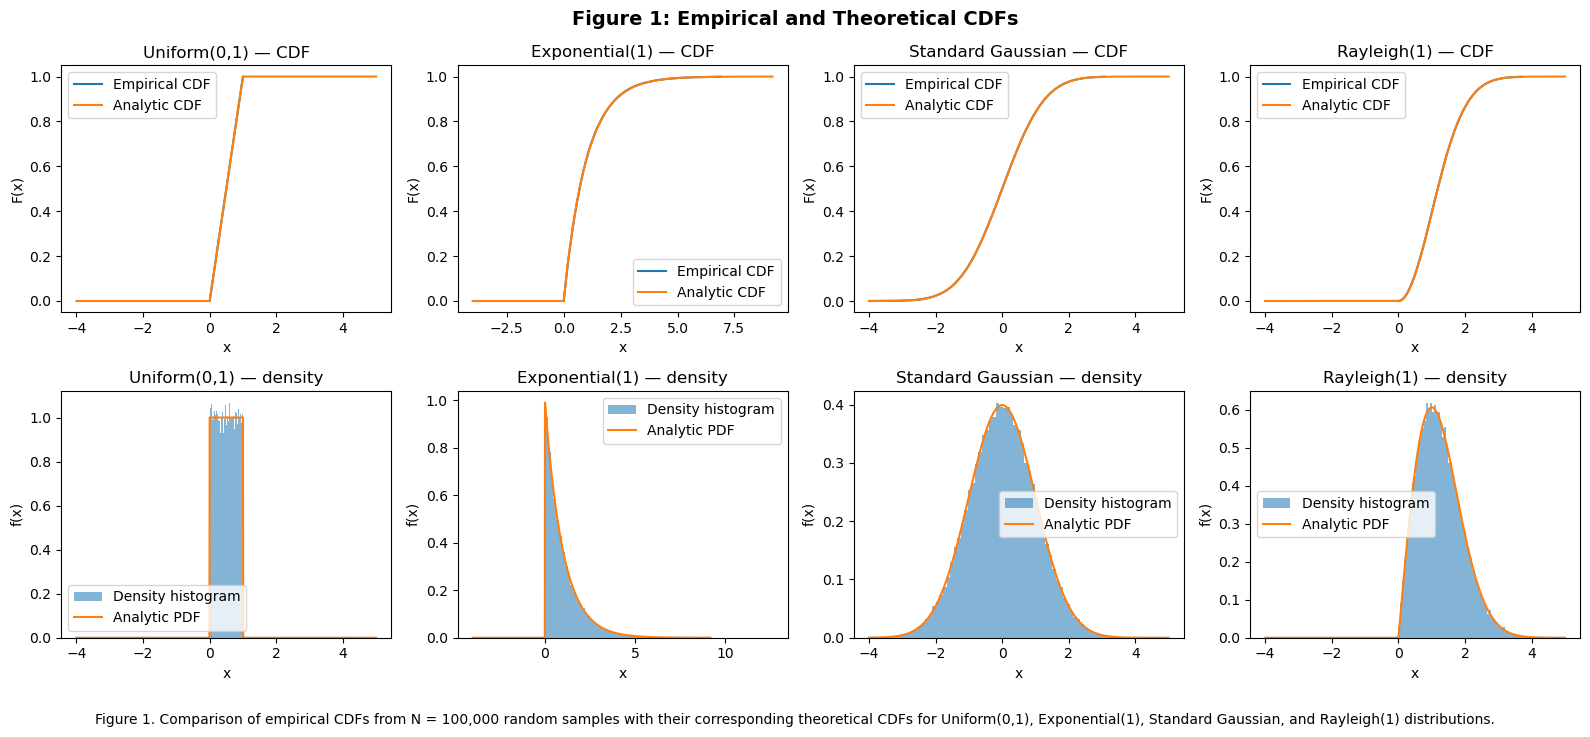

Distribution            KS statistic  95% critical  Below critical?
Uniform(0,1)                0.002126      0.004301             True
Exponential(1)              0.002759      0.004301             True
Standard Gaussian           0.001955      0.004301             True
Rayleigh(1)                 0.002447      0.004301             True


In [4]:
#Define the theoretical CDFs and PDFs to be compared with simulated distributions generated from random samples
#cdfs
def uniform_cdf(x):
    return np.clip(x, 0, 1)
def exponential_cdf(x):
    return np.where(x < 0, 0.0, -np.expm1(-x))
def gaussian_cdf(x):
    return ndtr(x)
def rayleigh_cdf(x):
    return np.where(x < 0, 0.0, -np.expm1(-x**2 / 2))
#pdfs
def uniform_pdf(x):
    return np.where((x >= 0) & (x <= 1), 1.0, 0.0)
def exponential_pdf(x):
    return np.where(x >= 0, np.exp(-x), 0.0)
def gaussian_pdf(x):
    return np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
def rayleigh_pdf(x):
    return np.where(x >= 0, x * np.exp(-x**2 / 2), 0.0)

#Organize the random samples
samples = {"Uniform(0,1)": uniform_samples, 
           "Exponential(1)": exponential_samples, 
           "Standard Gaussian": gaussian_samples, 
           "Rayleigh(1)": rayleigh_samples}

#Organize the theoretical CDFs
cdfs = {"Uniform(0,1)": uniform_cdf,
        "Exponential(1)": exponential_cdf,
        "Standard Gaussian": gaussian_cdf,
        "Rayleigh(1)": rayleigh_cdf}

#Organize the theoretical PDFs
pdfs = {"Uniform(0,1)": uniform_pdf,
        "Exponential(1)": exponential_pdf,
        "Standard Gaussian": gaussian_pdf,
        "Rayleigh(1)": rayleigh_pdf}

#Plots of the empirical CDFs against the analytic CDFs for the different distributions
critical = 1.36 / np.sqrt(N)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
ks_rows = []
for j, (name, x) in enumerate(samples.items()):
    xs = np.sort(x)
    ecdf = np.arange(1, N+1) / N
    grid = np.linspace(min(-4, x.min()), max(5, np.quantile(x, .9999)), 1200)
    axes[0, j].plot(xs[::100], ecdf[::100], label="Empirical CDF")
    axes[0, j].plot(grid, cdfs[name](grid), label="Analytic CDF")
    axes[0, j].set(title=name + " — CDF", xlabel="x", ylabel="F(x)")
    axes[0, j].legend()

    #Plots of the normalized histogram against the analytic PDFs for the different distributions
    axes[1, j].hist(x, bins=80, density=True, alpha=.55, label="Density histogram")
    axes[1, j].plot(grid, pdfs[name](grid), label="Analytic PDF")
    axes[1, j].set(title=name + " — density", xlabel="x", ylabel="f(x)")
    axes[1, j].legend()

    """Compare the KS statistic which provides the max gap between empirical and analytic CDFs 
    for each distribution against the 95% critical value at sample size 100000 which is .0043"""
    ks = ks_statistic(x, cdfs[name])
    ks_rows.append((name, ks, critical, ks < critical))

#Add the overall figure title
fig.suptitle("Figure 1: Empirical and Theoretical CDFs", fontsize=14, fontweight="bold")

#Add a caption underneath the grid
fig.text(0.5, -0.04, "Figure 1. Comparison of empirical CDFs from N = 100,000 "
"random samples with their corresponding theoretical CDFs "
"for Uniform(0,1), Exponential(1), Standard Gaussian, "
"and Rayleigh(1) distributions.", ha="center", fontsize=10, wrap=True)

plt.tight_layout()
plt.show()
print(f"{'Distribution':22s} {'KS statistic':>13s} {'95% critical':>13s} {'Below critical?':>16s}")
for row in ks_rows:
    print(f"{row[0]:22s} {row[1]:13.6f} {row[2]:13.6f} {str(row[3]):>16s}")

Figure 1 compares empirical cumulative distribution functions or CDFs for 100,000 simulated samples to their corresponding theoretical CDFs obtained analytically. The distribution functions include Uniform(0,1), Exponential(1), Standard Gaussian, and Rayleigh(1). As one can see by the graph, the empirical CDFs closely follow the theoretical CDFs, which means that the generated random samples match the expected probability distributions. The Uniform distribution shows that as the CDF increases linearly from 0 to 1 over the interval [0,1]. The Exponential distribution shows that a rapid increase occurs near 0 and gradually approaches 1 as x increases. The Standard Gaussian has an S shape CDF centered at 0 and a symmetric distribution. The Rayleigh starts at 0 and increases to 1 with the majority of probability around positive values. Although the curves may seem similar there are some small differences that are due to the finite number of samples in the empirical curve.

After all, the visual comparison is supported by the Kolmogorov–Smirnov or KS test, which measures the max difference between empirical and theoretical CDFs. Therefore, for N=100,000 samples the 95% critical value for the distributions is .0043. As one can see by the table the Uniform distribution has a KS statistic of around .0021, the Exponential distribution has a KS statistic of around .0028, the Standard Gaussian distribution has a KS statistic of around .002, and the Rayleigh distribution has a KS statistic of around .0024. Thus, since the KS statistics for all the distributions are below the value, it indicates that the difference between theoretical and empirical isn't large enough to reject the distributions. 

For the PDFs, the density histogram show the distribution for a simulated 100,000 random samples against the theoretical probability density functions for Uniform(0,1), Exponential(1), Standard Gaussian, and Rayleigh(1). As one can see by the graph, the Uniform distribution in the density histogram is constant between 0 and 1 and matches the theoretical PDF with a density of 1 throughout the interval, which means that the samples are distributed uniformly. The Exponential distribution has the highest density near 0 and decreases as x increases, which follows the theoretical PDF to show that larger sample values occur less frequently. The Standard Gaussian distribution shows that the histogram forms a bell shaped curve centered at 0 and high density near the mean 0. This matches the theoretical PDF because for both cases the density decreases symmetrically in the positive and negative direction. The Rayleigh distribution histogram shows that at x=0, the density is near 0, and as x increases the distribution also increases to its max and decreases afterward. This matches the theoretical PDF because they are both proportional to x. In conclusion, the small difference in the histogram is due to the random finite number samples.

In [5]:
#Standard Error Calculations
#Organize the existing random samples
distributions = {"Uniform(0,1)": uniform_samples,  "Gaussian": gaussian_samples, "Rayleigh(1)": rayleigh_samples, "Exponential(1)": exponential_samples}
#Print table headings
print(f"{'Distribution':22s} {'CDF Standard Error':>20s} {'PDF Standard Error':>20s}")
#Calculate standard errors for each distribution
for name, x in distributions.items():
    N = len(x)
    #CDF Standard Error
    #Sort the samples
    xs = np.sort(x)
    #Calculate empirical CDF
    ecdf = np.arange(1, N + 1) / N
    #Calculate CDF standard error at each point
    cdf_se = np.sqrt(ecdf * (1 - ecdf) / N)
    #Report maximum CDF standard error
    max_cdf_se = np.max(cdf_se)
    
    #PDF Standard Error
    #Calculate histogram counts and bin edges
    counts, edges = np.histogram(x, bins=80)
    #Calculate bin widths
    widths = np.diff(edges)
    #Calculate probability in each bin
    p = counts / N
    #Calculate PDF standard error for each bin
    pdf_se = np.sqrt(p * (1 - p) / N) / widths
    #Report maximum PDF standard error
    max_pdf_se = np.max(pdf_se)
    #Print results
    print(f"{name:22s} {max_cdf_se:20.6f} {max_pdf_se:20.6f}")

Distribution             CDF Standard Error   PDF Standard Error
Uniform(0,1)                       0.001581             0.029035
Gaussian                           0.001581             0.006041
Rayleigh(1)                        0.001581             0.010033
Exponential(1)                     0.001581             0.007084


Closed Form formulas:

Exponential:

Mean:

1/λ = 1/1 = 1
<br>
<br>
Median:

ln2/λ = .6931
<br>
<br>
Variance:

1/λ^2 = 1/1^2 = 1
<br>
<br>
<br>
<br>
Rayleigh:

Mean:

σsqrt(π/2) = 1sqrt(π/2) = 1.2533

Median:

σsqrt(2ln2) = 1sqrt(2ln2) = 1.1774

Variance:

[(4-π)/2]σ^2 = [(4-π)/2]1^2 = .4292

In [6]:
#Compute Sample mean, median, and variance to compare with for exponential and Rayleigh to compare with the closed form
print("Distribution      sample mean   theory mean   sample median   theory median   sample variance   theory variance")
exp_x = samples["Exponential(1)"]
ray_x = samples["Rayleigh(1)"]
moment_rows = [("Exponential", exp_x.mean(), 1.0, np.median(exp_x), np.log(2), exp_x.var(), 1.0), ("Rayleigh", ray_x.mean(), np.sqrt(np.pi/2), np.median(ray_x), np.sqrt(2*np.log(2)), ray_x.var(), 2-np.pi/2),]
for row in moment_rows:
    print(f"{row[0]:13s} {row[1]:12.6f} {row[2]:12.6f} {row[3]:14.6f} {row[4]:14.6f} {row[5]:16.6f} {row[6]:15.6f}")

Distribution      sample mean   theory mean   sample median   theory median   sample variance   theory variance
Exponential       0.998810     1.000000       0.695466       0.693147         0.993239        1.000000
Rayleigh          1.252496     1.253314       1.176152       1.177410         0.428802        0.429204


The closed form values are the theoretical values for the distributions and the sample values were calculated using the 100,000 random samples, which is why the results are slightly different. Thus, we can see that by increasing the samples, the values will approach their theoretical values.

The exponential distribution is right skewed in the density histogram, which has allowed the mean to be larger than the median and is why there is a factor of 1.44. The Gaussian mean and median coincide because in the density histogram one may see that it is symmetric about 0, which has allowed for an even distribution on both sides.

## Step 2: Build your own generator by inversion

If U is uniform on [0,1] and F is a continuosly increasing CDF, we can prove the inverse has CDF F.

$$F(x) = \frac{x-a}{b-a} = u$$

If we set the probability of the uniform distribution to U, we can solve in terms of X.

$$F^{-1}(u) = a + (b - a)u = x$$

When a = 0 and b = 1,

$$F^{-1}(u) = u = x$$ so $$u = x$$

To derive $$F^(-1)$$ for the exponential, we follow a similar path as before.

The PDF of the exponential is $$f(x) = \lambda e^{-\lambda x}$$

From there, the CDF is $$F(x) = 1-e^{-\lambda x}$$

We define u as $$u = 1-e^{-\lambda x}$$

$$u-1 = -e^{-\lambda x}$$

$$1-u = e^{-\lambda x}$$
$$ln(1-u) = ln(e^{-\lambda x})$$
$$-\frac{1}{\lambda} ln(1-u) = x$$

For the Rayleigh, we can use the same process:

$$f(x) = \frac{x}{\sigma^2} e^{\frac{-x^2}{2\sigma ^2}}$$

The CDF is:

$$f(x) = 1 - e^{\frac{-x^2}{2\sigma ^2}} = u$$

$$u = 1 - e^{\frac{-x^2}{2\sigma ^2}}$$

$$u - 1 = e^{\frac{-x^2}{2\sigma ^2}}$$

$$ln (u - 1) = ln(e^{\frac{-x^2}{2\sigma ^2}})$$

$$ln (u - 1) = \frac{-x^2}{2\sigma ^2}$$

$$2\sigma^2 ln (u - 1) = {-x^2}$$

$$\sqrt{-2\sigma^2 ln (u - 1)} = x$$

Rayleigh KS statistic: 0.003091
Exponent KS statistic: 0.001696


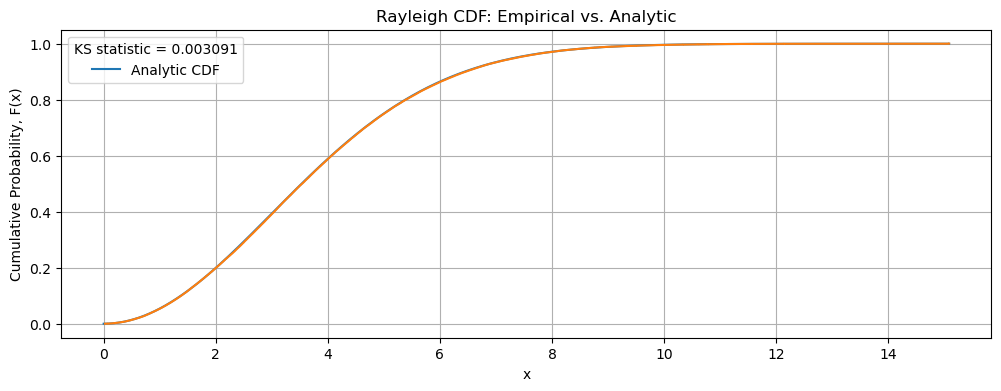

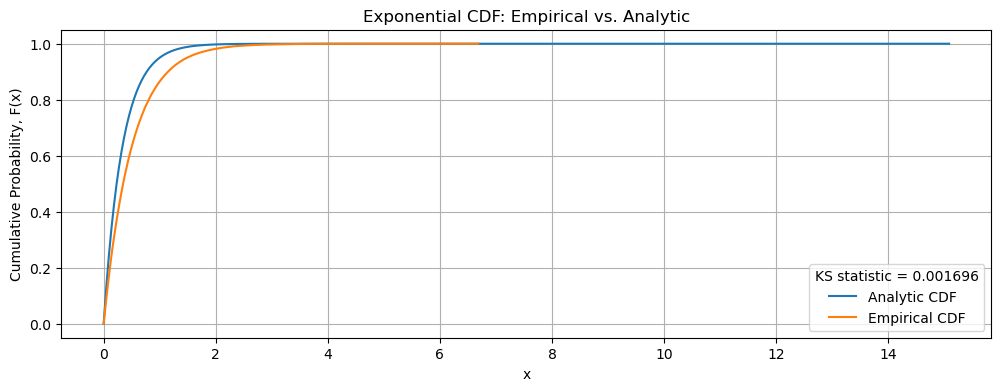

In [7]:
n = 100000

ray_samples  = sample_by_inversion(inv_cdf_rayleigh, n, rng, sigma=3.0)

exp_samples = sample_by_inversion(inv_cdf_exponential, n, rng, lam=2.0)



def cdf_rayleigh(x, sigma):
    x = np.asarray(x, dtype=float)
    return 1 - np.exp(-(x**2) / (2 * sigma**2))
    
def cdf_exp(x, lamb):
    return 1 - np.exp(-lamb*x)
sigma = 3.0
lamb = 2.0
ks_rayleigh = ks_statistic(ray_samples, lambda x: cdf_rayleigh(x, sigma))
print(f"Rayleigh KS statistic: {ks_rayleigh:.6f}")


ks_exp = ks_statistic(exp_samples, lambda x: cdf_exp(x, lamb))
print(f"Exponent KS statistic: {ks_exp:.6f}")


# Plot the histogram for Rayleigh
#plt.hist(ray_samples, bins=100, density=True, alpha=0.7, color='blue', edgecolor='black')
#plt.title('Histogram of Rayleigh Samples via Inverse CDF Method')
#plt.xlabel('x')
#plt.ylabel('Density')
#plt.grid(True)

x_sorted = np.sort(ray_samples)
m = len(x_sorted)

p = np.arange(1, m + 1) / m
x_ray_grid = np.linspace(0, x_sorted.max(), 1000)

plt.plot(
    x_ray_grid,
    cdf_rayleigh(x_ray_grid, sigma),
    label="Analytic CDF"
)
plt.title("Rayleigh CDF: Empirical vs. Analytic")
plt.xlabel("x")
plt.ylabel("Cumulative Probability, F(x)")
plt.legend(title=f"KS statistic = {ks_rayleigh:.6f}")
plt.grid(True)


plt.step(x_sorted, p, where="post", label="Empirical CDF")
plt.show()

# Plot the histogram for Exponential
#plt.figure(figsize=(10, 6))
#plt.hist(exp_samples, bins=100, density=True, alpha=0.7, color='blue', edgecolor='black')
#plt.title('Histogram of Exponential Samples via Inverse CDF Method')
#plt.xlabel('x')
#plt.ylabel('Density')
#plt.grid(True)
x2_sorted = np.sort(exp_samples)
m2 = len(x2_sorted)

p = np.arange(1, m2 + 1) / m2
x_ray_grid = np.linspace(0, x_sorted.max(), 1000)

plt.plot(
    x_ray_grid,
    cdf_exp(x_ray_grid, sigma),
    label="Analytic CDF"
)

plt.step(x2_sorted, p, where="post", label="Empirical CDF")
plt.title("Exponential CDF: Empirical vs. Analytic")
plt.xlabel("x")
plt.ylabel("Cumulative Probability, F(x)")
plt.legend(title=f"KS statistic = {ks_exp:.6f}")
plt.grid(True)
plt.show()

My function uses the inverse exponential CDF form of 
$$F^{-1}(u) = \frac{-ln(1-u)}{\lambda}$$ 

and 
$$F^{-1}{u} = \sigma \sqrt{2ln(1-u)}$$ for the inverse Rayleigh form.

When u = 0, both forms will have ln(1) = 0, which will safely fail by becoming zero instead of infinity.  However, additional code was added to prevent it from being exactly 1, which could lead to ln(0), which is infinity.  This means the range is [0,1), with it not including 1 exactly.

My function uses the inverse exponential CDF form of 
$$F^{-1}(u) = \frac{-ln(1-u)}{\lambda}$$ 

and 
$$F^{-1}{u} = \sigma \sqrt{2ln(1-u)}$$ for the inverse Rayleigh form.

When u = 0, both forms will have ln(1) = 0, which will safely fail by becoming zero instead of infinity.  However, additional code was added to prevent it from being exactly 1, which could lead to ln(0), which is infinity.  This means the range is [0,1), with it not including 1 exactly.

The exponential inverse can be written either 
$$-\frac{ln(1-U)}{\lambda}$$

or

$$-\frac{ln(U)}{\lambda}$$

Both of these results are the same, but we use the second one because we will not have the same issue with the edge case of zero.  Instead of going to infinity, the function will fail safely by returning zero.

## Step 3: A function of a random variable

Let $X\sim N(0,1)$ and define $Y=X^2$.

#### Derive the CDF

Since $Y=X^2\ge0$, we have $F_Y(y)=0$ for $y<0$.

For $y\ge0$,
$$
\begin{aligned}
F_Y(y)
&=P(Y\le y)\\
&=P(X^2\le y)\\
&=P(-\sqrt y\le X\le\sqrt y)\\
&=F_X(\sqrt y)-F_X(-\sqrt y)\\
&=\Phi(\sqrt y)-\Phi(-\sqrt y).
\end{aligned}
$$

Using $\Phi(-z)=1-\Phi(z)$,
$$
\boxed{
F_Y(y)=
\begin{cases}
0, & y<0,\\
2\Phi(\sqrt y)-1, & y\ge0.
\end{cases}
}
$$

Both positive and negative values of $X$ contribute to $Y$.

#### Differentiate to obtain the PDF

For $y>0$, apply the chain rule:
$$
\begin{aligned}
f_Y(y)
&=\frac{d}{dy}
  \left[F_X(\sqrt y)-F_X(-\sqrt y)\right]\\
&=\frac{f_X(\sqrt y)}{2\sqrt y}
  +\frac{f_X(-\sqrt y)}{2\sqrt y}.
\end{aligned}
$$

The standard Gaussian density is symmetric, so
$$
\boxed{
f_Y(y)=\frac{e^{-y/2}}{\sqrt{2\pi y}},
\qquad y>0.
}
$$

#### Why the density diverges near zero

$dy/dx=2x=0$ at $x=0$.

The interval $-\varepsilon\le X\le\varepsilon$ is compressed into
$0\le Y\le\varepsilon^2$. Its probability is approximately
$2f_X(0)\varepsilon$, so the average density over the resulting
interval is approximately
$$
\frac{2f_X(0)\varepsilon}{\varepsilon^2}
=\frac{2f_X(0)}{\varepsilon},
$$
which grows without bound as $\varepsilon\to0$.

The divergence is integrable. Using $y=t^2$,
$$
\int_0^\infty f_Y(y)\,dy
=
\sqrt{\frac{2}{\pi}}
\int_0^\infty e^{-t^2/2}\,dt
=1.
$$

Also, $F_Y(0)=0$, so the divergence does not create a point mass at zero.

Near zero,
$$
f_Y(y)\sim\frac{1}{\sqrt{2\pi}}y^{-1/2}.
$$

Therefore, the limiting slope on log-log axes is $-1/2$.

In [8]:
step3_start = perf_counter()
rng_step3 = rng_step[2]

integral3, integration_error3 = quad(
    squared_gaussian_pdf,
    0.0,
    np.inf,
    epsabs=1e-10,
    epsrel=1e-10,
    limit=200
)

print(f"Integral of f_Y: {integral3:.12f}")
print(f"Difference from 1: {integral3 - 1:+.3e}")
print(f"Estimated quadrature error: {integration_error3:.3e}")

Integral of f_Y: 1.000000000001
Difference from 1: +6.197e-13
Estimated quadrature error: 2.011e-11


#### Probabilities and median

From the derived CDF,
$$
P(Y\le1)=2\Phi(1)-1\approx0.68268949,
$$
and
$$
P(Y\le0.1)
=2\Phi(\sqrt{0.1})-1
\approx0.24817037.
$$

The median $m$ satisfies $F_Y(m)=1/2$, so
$$
2\Phi(\sqrt m)-1=\frac12.
$$

Therefore,
$$
\boxed{
m=\left[\Phi^{-1}(0.75)\right]^2
\approx0.45493642.
}
$$

#### Mean and variance

Using the lecture's expectation formula for a function of a random variable,
$$
E[Y]=E[X^2]
=\operatorname{Var}(X)+(E[X])^2
=1.
$$

For the standard Gaussian, $f_X'(x)=-xf_X(x)$. Integration by parts gives
$$
\begin{aligned}
E[X^4]
&=-\int_{-\infty}^{\infty}x^3f_X'(x)\,dx\\
&=-[x^3f_X(x)]_{-\infty}^{\infty}
  +3\int_{-\infty}^{\infty}x^2f_X(x)\,dx\\
&=3.
\end{aligned}
$$

Hence,
$$
\boxed{
\operatorname{Var}(Y)
=E[X^4]-(E[X^2])^2
=3-1=2.
}
$$

In [9]:
N3 = 1_000_000
X3 = rng_step3.standard_normal(N3)
Y3 = X3**2

print(f"Step 3 sample count: {N3:,}")
print(
    f"{'Probability':<16} {'Analytic':>12} {'Monte Carlo':>12} "
    f"{'Difference':>13} {'Estimated SE':>14}"
)

probability_rows3 = []

for cutoff3 in [1.0, 0.1]:
    exact3 = float(squared_gaussian_cdf(cutoff3))
    estimate3 = float(np.mean(Y3 <= cutoff3))
    se3 = np.sqrt(estimate3 * (1 - estimate3) / N3)

    probability_rows3.append(
        (cutoff3, exact3, estimate3, se3)
    )

    print(
        f"{'P[Y <= '+str(cutoff3)+']':<16} "
        f"{exact3:12.8f} {estimate3:12.8f} "
        f"{estimate3-exact3:+13.8f} {se3:14.8f}"
    )

median_theory3 = float(ndtri(0.75)**2)

moment_rows3 = [
    ("Median", median_theory3, float(np.median(Y3))),
    ("Mean", 1.0, float(Y3.mean())),
    ("Variance", 2.0, float(Y3.var(ddof=1)))
]

print("\nSample variance uses ddof=1.")
print(
    f"{'Quantity':<12} {'Analytic':>12} "
    f"{'Monte Carlo':>12} {'Difference':>13}"
)

for label3, exact3, estimate3 in moment_rows3:
    print(
        f"{label3:<12} {exact3:12.8f} "
        f"{estimate3:12.8f} {estimate3-exact3:+13.8f}"
    )

D3 = ks_statistic(Y3, squared_gaussian_cdf)
critical3 = 1.36 / np.sqrt(N3)

print(
    f"\nKS statistic: {D3:.8f}; "
    f"95% critical value: {critical3:.8f}"
)
print("Reject at 5%?", D3 > critical3)

Step 3 sample count: 1,000,000
Probability          Analytic  Monte Carlo    Difference   Estimated SE
P[Y <= 1.0]        0.68268949   0.68172400   -0.00096549     0.00046581
P[Y <= 0.1]        0.24817037   0.24834500   +0.00017463     0.00043205

Sample variance uses ddof=1.
Quantity         Analytic  Monte Carlo    Difference
Median         0.45493642   0.45497635   +0.00003992
Mean           1.00000000   1.00280702   +0.00280702
Variance       2.00000000   2.01626717   +0.01626717

KS statistic: 0.00104379; 95% critical value: 0.00136000
Reject at 5%? False


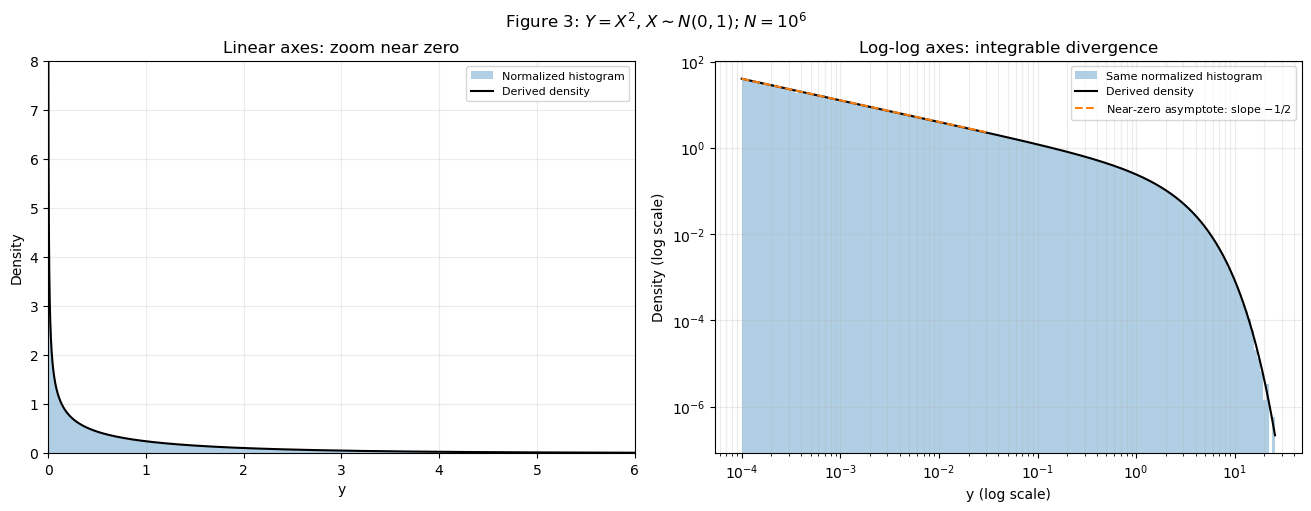

Histogram area: 1.000000000000; samples included: 1,000,000


In [10]:
edges3 = np.r_[
    0.0,
    np.geomspace(1e-4, max(12, Y3.max()*1.001), 180)
]

counts3, _ = np.histogram(Y3, bins=edges3)
density3 = counts3 / (N3 * np.diff(edges3))
area3 = float(np.sum(density3 * np.diff(edges3)))

grid3 = np.geomspace(edges3[1], edges3[-1], 1800)

fig3, axes3 = plt.subplots(
    1, 2, figsize=(13, 5), layout="constrained"
)

axes3[0].stairs(
    density3, edges3,
    fill=True, alpha=0.35,
    label="Normalized histogram"
)
axes3[0].plot(
    grid3, squared_gaussian_pdf(grid3),
    "k-", label="Derived density"
)
axes3[0].set(
    xlim=(0, 6),
    ylim=(0, 8),
    xlabel="y",
    ylabel="Density",
    title="Linear axes: zoom near zero"
)

# Omit the zero-edge bin from the log display only.
axes3[1].stairs(
    density3[1:], edges3[1:],
    fill=True, alpha=0.35,
    label="Same normalized histogram"
)
axes3[1].plot(
    grid3, squared_gaussian_pdf(grid3),
    "k-", label="Derived density"
)

near_zero3 = np.geomspace(1e-4, 0.03, 200)
axes3[1].plot(
    near_zero3,
    1 / np.sqrt(2*np.pi*near_zero3),
    "--",
    label=r"Near-zero asymptote: slope $-1/2$"
)

axes3[1].set(
    xscale="log",
    yscale="log",
    xlabel="y (log scale)",
    ylabel="Density (log scale)",
    title="Log-log axes: integrable divergence"
)

for ax3 in axes3:
    ax3.legend(fontsize=8)
    ax3.grid(True, which="both", alpha=0.25)

fig3.suptitle(
    r"Figure 3: $Y=X^2$, $X\sim N(0,1)$; $N=10^6$"
)

plt.show()

print(
    f"Histogram area: {area3:.12f}; "
    f"samples included: {counts3.sum():,}"
)

Logarithmic bins help clarify the rapid increase in density near zero. A linear-scale plot offers limited vertical range to see the distribution's shape near the origin, whereas a log-log plot shows a limiting slope of -1/2. Bins that would start at zero are excluded from a logarithmic-scale plot.

Using a fixed random seed for a new simulation, the histogram contains all 1,000,000 samples and has an area of 1. The Kolmogorov-Smirnov (KS) statistic is approximately 0.00104379, which is below the critical value of 0.00136 (at a 95% confidence level); therefore, the test does not reject the specified cumulative distribution function (CDF).

The empirical median is approximately 0.454976, while the empirical mean is approximately 1.002807. The discrepancy between these two values is consistent with a right-skewed distribution: a significant portion of the probability mass is concentrated near zero. In contrast, observations with larger values pull the mean upward.

## Step 4: Expectation and moments

In [11]:
print(np.random.default_rng().integers(0, 2**31))

1270177385


In [12]:
rng_step4 = rng.spawn(1)[0]

print("Part 1 - Rayleigh Moments")

N_rayleigh = 1000000
rayleigh_samples = rng_step4.rayleigh(scale = 1.0, size = N_rayleigh) 

# first four moments
true_moments = { 
    1: np.sqrt(np.pi / 2.0 ),
    2: 2.0,
    3: 3 * np.sqrt(np.pi / 2.0),
    4: 8.0 
}
for k in [1, 2, 3, 4]:
    sample_kth = rayleigh_samples ** k
    estimate_moment = np.mean(sample_kth)
    true_moment = true_moments[k]

    #units in standard error
std_error = np.std(sample_kth, ddof = 1) / np.sqrt(N_rayleigh)

z_score = np.abs(estimate_moment - true_moment) / std_error 

print(f"Moment {k}: Estimated = {estimate_moment:.4f} | True = {true_moment:.4f} | Diff = {z_score:.4f} std errors")  

pareto_samples = rng_step4.pareto(a=1.5, size = 1000000) + 1

cp = [1000, 10000, 100000, 1000000] 

print(f"{"N":>10} | {"Sample Mean (True = 3)" :>25} | {"Sample Variance (True = Inf)" :>30}") 
print("-" * 72)

print("Part 2 - Pareto Distribution")

# pareto samples 
pareto_samples = rng_step4.pareto(a=1.5, size = 1000000) + 1
N_pareto = [1000, 10000, 100000, 1000000]

print(f"{'N':>10} | {'Sample Mean (True = 3.0)':>25} | {'Sample Variance (True = INF)':>30}") 

print("_" * 72) 

for n in N_pareto: 
    subset = pareto_samples[:n]
    mean_val = np.mean(subset)
    variance_val = np.var(subset, ddof=1)

print(f"{n:>10} | {mean_val:>25.4f} | {variance_val:>30.4f}")

Part 1 - Rayleigh Moments
Moment 4: Estimated = 8.0260 | True = 8.0000 | Diff = 1.4553 std errors
         N |    Sample Mean (True = 3) |   Sample Variance (True = Inf)
------------------------------------------------------------------------
Part 2 - Pareto Distribution
         N |  Sample Mean (True = 3.0) |   Sample Variance (True = INF)
________________________________________________________________________
   1000000 |                    2.9630 |                       245.4991


Figure 4


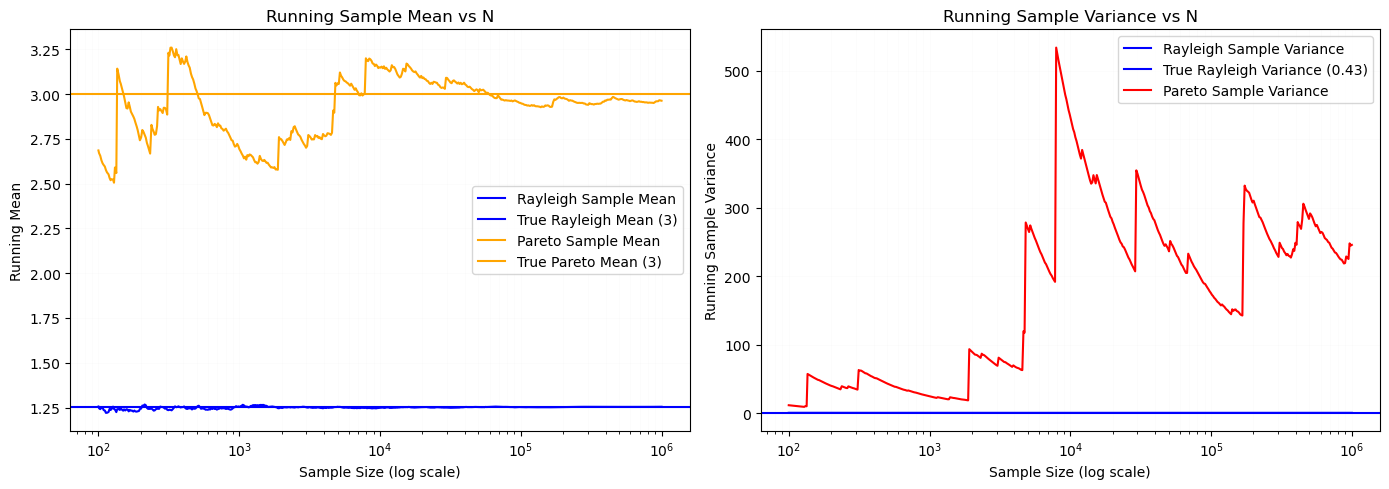

In [13]:
print("Figure 4")

indices = np.arange(1, 1000001) 

pareto_cumsum = np.cumsum (pareto_samples)
pareto_running_mean = pareto_cumsum / indices
pareto_cumsum_square = np.cumsum(pareto_samples ** 2) 
pareto_running_variance = (pareto_cumsum_square - indices * (pareto_running_mean ** 2)) / np.maximum(indices - 1, 1)

rayleigh_cumsum = np.cumsum (rayleigh_samples)
rayleigh_running_mean = rayleigh_cumsum / indices
rayleigh_cumsum_square = np.cumsum(rayleigh_samples ** 2) 
rayleigh_running_variance = (rayleigh_cumsum_square - indices * (rayleigh_running_mean ** 2)) / np.maximum(indices - 1, 1)

figure_4 = np.unique(np.logspace(2, 6, num=500).astype(int)) - 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

ax1.plot(figure_4 + 1, rayleigh_running_mean[figure_4], label = "Rayleigh Sample Mean", color ="blue")
ax1.axhline(true_moments[1], color ="blue" , label = "True Rayleigh Mean (3)")

ax1.plot(figure_4 + 1, pareto_running_mean[figure_4], label = "Pareto Sample Mean", color ="orange")
ax1.axhline(3.0, color ="orange" , label = "True Pareto Mean (3)") 

ax1.set_xscale("log")
ax1.set_xlabel("Sample Size (log scale)")
ax1.set_ylabel("Running Mean")
ax1.set_title("Running Sample Mean vs N")
ax1.legend()
ax1.grid(True, which = "both", alpha = .03) 

true_rayleigh_variance = 2 - np.pi / 2
ax2.plot(figure_4 + 1, rayleigh_running_variance[figure_4], label = "Rayleigh Sample Variance", color = "blue")
ax2.axhline(true_rayleigh_variance, color = "blue", label = f"True Rayleigh Variance ({true_rayleigh_variance:.2f})")

ax2.plot(figure_4 +1, pareto_running_variance[figure_4], label = "Pareto Sample Variance", color = "red")

ax2.set_xscale("log")
ax2.set_xlabel("Sample Size (log scale)")
ax2.set_ylabel("Running Sample Variance")
ax2.set_title("Running Sample Variance vs N")
ax2.legend()
ax2.grid(True, which = "both", alpha = .03) 

plt.tight_layout()
plt.show()

### Step 5: The central limit theorem, and where it fails

Mean and Variance of the Sum of N Uniform

The mean of one Uniform(0,1) random variable is:

E[X_i] = 1/2

The variance of one Uniform(0,1) random variable is:

Var(X_i) = 1/12

The sum of (N) independent Uniform(0,1) random variables is:

S_N = X_1 + X_2 + ... + X_N

Using independence, the mean and variance of the sum are:

E[S_N] = N/2

Var(S_N) = N/12
<br>
<br>
<br>
<br>
The mean of a sum of N Pareto variables

E[X] = α / (α-1) = 3

E[S_N] = 3N


In [14]:
#Standardize each sum to zero mean and unit variance while reporting KS statistic against standard normal CDF
r = rng_step[4]
M = 200_000
uniform_ns = [1, 2, 3, 5, 10, 30]

#Print the theoretical mean and variance of the uniform sums
print("Theoretical mean and variance of uniform sums:")
print("N       Mean       Variance")
for n in uniform_ns:
    mean_sum = n / 2
    variance_sum = n / 12
    print(f"{n:<7} {mean_sum:<10.4f} {variance_sum:.4f}")

uniform_ks = []
uniform_sums = {}
#Each row contains n independent Uniform(0,1) values
for n in uniform_ns:
    sums = r.random((M, n)).sum(axis=1)
    z = (sums - n/2) / np.sqrt(n/12)
    uniform_sums[n] = z
    uniform_ks.append(ks_statistic(z, ndtr))
uniform_critical = 1.36/np.sqrt(M)
print("Uniform sums compared with Standard Normal CDF")
print("N KS Statistic 95% Critical Value")
for n, d in zip(uniform_ns, uniform_ks):
    print(n, f"{d:.6f}", f"{uniform_critical:.6f}")

#Pareto experiment, which is centered by the finite mean and scale by N^(1/alpha);
#This is the natural heavy-tail scaling, not a variance standardization
#Report KS statistic using Pareto
pareto_ns = [1, 10, 100, 1000]
pareto_ks = []
pareto_zs = {}
alpha = 1.5
for n in pareto_ns:
    vals = r.pareto(alpha, size=(M, n)) + 1
    sums = vals.sum(axis=1)
    z = (sums - n*3.0) / (n**(1/alpha))
    pareto_zs[n] = z
    pareto_ks.append(ks_statistic(z, ndtr))
#Calculate the 95% KS critical value
pareto_critical = 1.36 / np.sqrt(M)

#Print the theoretical mean and KS critical value
print("\nPareto sums: Mean and KS comparison against Standard Normal CDF")
print("N       Mean of Sum       KS Statistic       95% Critical Value")

for n, d in zip(pareto_ns, pareto_ks):
    mean_sum = n * 3.0
    print(f"{n:<7} {mean_sum:<17.4f} {d:<18.6f} {pareto_critical:.6f}")
print("\nPareto centered, heavy-tail-scaled sums vs standard normal:")
for n, d in zip(pareto_ns, pareto_ks):
    print(n, f"{d:.6f}")

Theoretical mean and variance of uniform sums:
N       Mean       Variance
1       0.5000     0.0833
2       1.0000     0.1667
3       1.5000     0.2500
5       2.5000     0.4167
10      5.0000     0.8333
30      15.0000    2.5000
Uniform sums compared with Standard Normal CDF
N KS Statistic 95% Critical Value
1 0.059335 0.003041
2 0.017902 0.003041
3 0.011740 0.003041
5 0.006004 0.003041
10 0.004708 0.003041
30 0.001271 0.003041

Pareto sums: Mean and KS comparison against Standard Normal CDF
N       Mean of Sum       KS Statistic       95% Critical Value
1       3.0000            0.487810           0.003041
10      30.0000           0.449463           0.003041
100     300.0000          0.428236           0.003041
1000    3000.0000         0.417116           0.003041

Pareto centered, heavy-tail-scaled sums vs standard normal:
1 0.487810
10 0.449463
100 0.428236
1000 0.417116


As one may see that for the uniform case as N increases the sum distribution becomes more Gaussian and fall like 1/sqrt(N). When the KS statistic is greater than .003, the difference from the Gaussian is detectable by around 5%, but when it's below, the test doesn't reject the standard normal model. Thus, when N=2X10^7 samples the 95% critical value is .003, which means that at N=30, the ditribution is still distinguishable from a Gaussian. It is also noticeable that from the Pareto, as N increases the KS statistic decreases to stay in the range of .3 and .45. Thus, the Pareto doesn't converge to the standard Gaussian distribution.

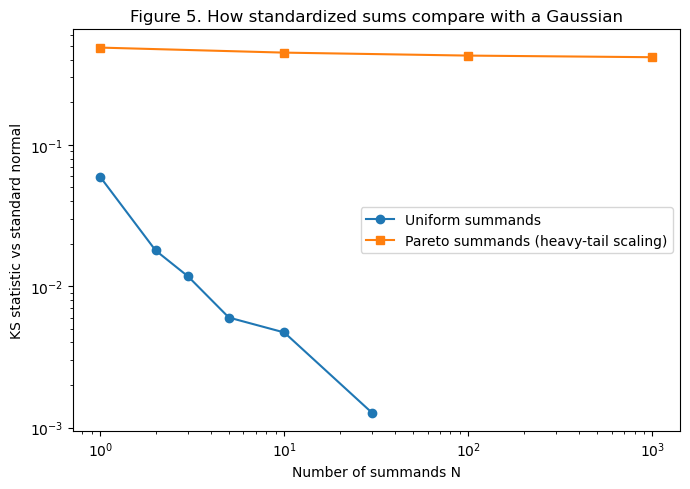

In [15]:
#plot figure 5 KS statistic against N on log-log axes, uniform summands and Pareto 
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(uniform_ns, uniform_ks, "o-", label="Uniform summands")
ax.loglog(pareto_ns, pareto_ks, "s-", label="Pareto summands (heavy-tail scaling)")
ax.set(xlabel="Number of summands N", ylabel="KS statistic vs standard normal",
       title="Figure 5. How standardized sums compare with a Gaussian")
ax.legend()
plt.tight_layout()
plt.show()

Figure 5 is comparing standardized sums for Pareto and Uniform distributions to Gaussian and as one can see that as N increases in the Uniform curve, the KS statistic decreases, which indicates that the stadardized sums are getting closer to the standard Gaussian distribution. We can also see that the Pareto curve doesn't show the same convergence toward zero, which indicates that the heavy tailed distribution has infinte variance and so the Gaussian CLT doesn't apply.

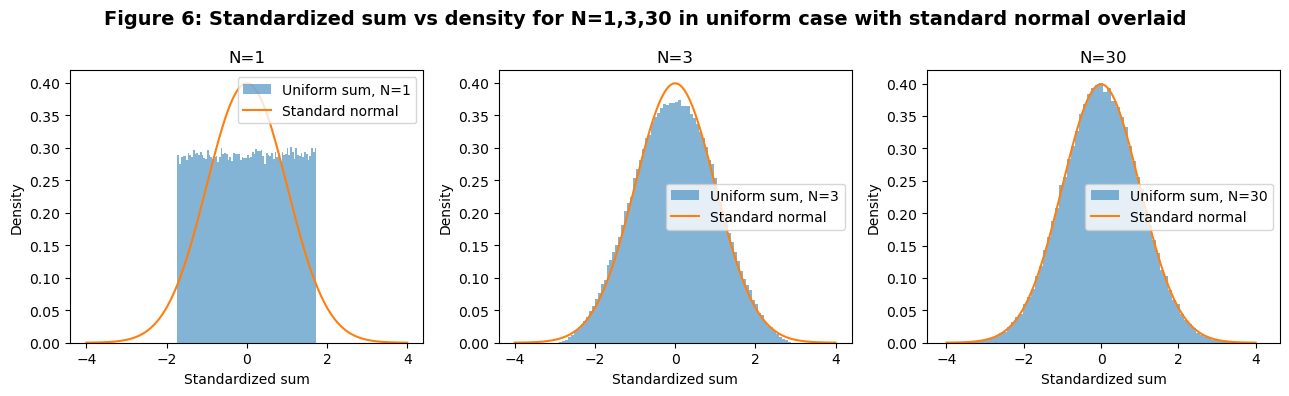

Uniform 95% KS critical value: 0.0030410524493997143


In [16]:
#Plot figure 6 Histograms of standardized sum of N=1,3,30 for uniform case with standard normal overlaid
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
grid = np.linspace(-4, 4, 500)
#Add the overall figure title
fig.suptitle("Figure 6: Standardized sum vs density for N=1,3,30 in uniform case with standard normal overlaid", fontsize=14, fontweight="bold")
for ax, n in zip(axes, [1, 3, 30]):
    ax.hist(uniform_sums[n], bins=80, density=True, alpha=.55, label=f"Uniform sum, N={n}")
    ax.plot(grid, np.exp(-grid**2/2)/np.sqrt(2*np.pi), label="Standard normal")
    ax.set(title=f"N={n}", xlabel="Standardized sum", ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.show()
print("Uniform 95% KS critical value:", uniform_critical)

The Figure 6 shows the standardized sum vs the density as n increases in the uniform case. As expected, as N increases it becomes similar to the standard normal Gaussian distribution. Thus, when N=1, the distribution looks to be Uniform and when N=3, the distribution gets closer to Gaussian. Finally, when N=30, the histogram resembles a standard normal curve. In conclusion, by increasing the number of independent uniform random variables makes the standardized sum look more like Gaussian, which is the predicted behavior by the Central Limit Theorem.

Even at N=30 the distribution is formally distinguishable from a Gaussian, and this is not a failure of the CLT or Central Limit Theorem because CLT states that the standardized sum of independent random variables with finite mean and variance approaches a Gaussian distribution as N increases, but since it doesn't state when the distribution becomes exactly Gaussian for a finite N, it is possible for the sample size of 200,000 to be large enough that the KS test can detect even very small differences between the standardized uniform sums and the standard normal distribution. Thus, there will be a small difference between the KS statistic and the 95% critical value at N=30. The difference between a distribution that is statistically distinguishable from Gaussian and one that is pratically different is that a statistically distinguishable distribution has a measurable difference according to a statistical test and a pratically different distribution has differences large enough to affect the shape or meaningful applications.

The Pareto distribution has a shape parameter of α = 1.5, a finite mean, and an infinite variance because α is less than or equal to 2, which causes the convergence to stall. Thus, the hypothesis of the central limit theorem that the Pareto violates is the hypothesis of finite variance because the Pareto has infinite variance. Therefore, the standardized sums don't converge to a Gaussian distribution and instead after centering by the mean and scaling by N^(-1/α), the sums converge to a non-Gaussian stable distribution with a stability of 1.5. In conclusion, the reason convergence stalls because Pareto produces extremely large values that have a large influence on the sum than the distribution with a finite variance.

## Step 6: A threshold detector in Gaussian noise

Under the noise-only hypothesis,
$$
H_0:\quad X\sim N(0,\sigma^2).
$$

Under the signal-plus-noise hypothesis,
$$
H_1:\quad X\sim N(A,\sigma^2).
$$

Here, $\sigma$ is the noise standard deviation.

#### Standardization and the Q function

Following the lecture, if $X\sim N(\mu,\sigma^2)$, then
$$
Z=\frac{X-\mu}{\sigma}\sim N(0,1).
$$

The Gaussian tail probability is
$$
Q(z)=P(Z>z)
=1-\Phi(z)
=\frac12\operatorname{erfc}\left(\frac{z}{\sqrt2}\right).
$$

#### Probability of false alarm

Under $H_0$,
$$
\begin{aligned}
P_{FA}
&=P(X>T\mid H_0)\\
&=P\left(\frac{X}{\sigma}>
         \frac{T}{\sigma}\mid H_0\right)\\
&=\boxed{Q\left(\frac{T}{\sigma}\right)}.
\end{aligned}
$$

#### Probability of detection

Under $H_1$,
$$
\begin{aligned}
P_D
&=P(X>T\mid H_1)\\
&=P\left(\frac{X-A}{\sigma}>
         \frac{T-A}{\sigma}\mid H_1\right)\\
&=\boxed{Q\left(\frac{T-A}{\sigma}\right)}.
\end{aligned}
$$

#### Choosing the threshold

Inverting the false-alarm equation gives
$$
{
\frac{T}{\sigma}
=Q^{-1}(P_{FA})
=\sqrt2\,\operatorname{erfc}^{-1}(2P_{FA}).
}
$$

For $A/\sigma=3$,
$$
\boxed{
P_D=Q\left(Q^{-1}(P_{FA})-3\right).
}
$$

In [17]:
step6_start = perf_counter()
rng_step6 = rng_step[5]

arguments6 = np.array([0.0, 3.0, 5.2])
q_library6 = q_function(arguments6)
q_reference6 = stats.norm.sf(arguments6)
q_error6 = np.abs(q_library6 - q_reference6)

print(
    f"{'x':>5} {'mp2lib Q(x)':>20} "
    f"{'Reference':>20} {'Absolute error':>16}"
)

for x6, q6, ref6, error6 in zip(
    arguments6, q_library6, q_reference6, q_error6
):
    print(
        f"{x6:5.1f} {q6:20.12e} "
        f"{ref6:20.12e} {error6:16.3e}"
    )

np.testing.assert_allclose(
    q_library6, q_reference6,
    rtol=1e-12, atol=0
)

print("Q-function verification passed, including a tail near 10^-7.")

    x          mp2lib Q(x)            Reference   Absolute error
  0.0   5.000000000000e-01   5.000000000000e-01        0.000e+00
  3.0   1.349898031630e-03   1.349898031630e-03        2.602e-18
  5.2   9.964426316933e-08   9.964426316933e-08        1.191e-22
Q-function verification passed, including a tail near 10^-7.


In [18]:
amplitude_ratio6 = 3.0
pfa_table6 = np.array([1e-2, 1e-3, 1e-4, 1e-6])

threshold_sigma6 = np.sqrt(2.0) * erfcinv(2.0*pfa_table6)
pd_table6 = q_function(threshold_sigma6 - amplitude_ratio6)

print("Threshold table for A/sigma = 3")
print(f"{'P_FA':>12} {'T/sigma':>14} {'P_D':>14}")

for pfa6, t6, pd6 in zip(
    pfa_table6, threshold_sigma6, pd_table6
):
    print(f"{pfa6:12.0e} {t6:14.8f} {pd6:14.8f}")

Threshold table for A/sigma = 3
        P_FA        T/sigma            P_D
       1e-02     2.32634787     0.74973375
       1e-03     3.09023231     0.46405131
       1e-04     3.71901649     0.23606538
       1e-06     4.75342431     0.03976460


#### Monte Carlo verification

Verify the rows for $P_{FA}=10^{-3}$ and $10^{-4}$.

Choosing $\sigma=1$ and $A=3$ preserves $A/\sigma=3$.
For each threshold, independently generate measurements under
$H_0$ and $H_1$ and $X>T$.

For $k$ events in $N$ independent trials,
$$
\widehat p=\frac{k}{N},
\qquad
\widehat{\operatorname{SE}}(\widehat p)
=\sqrt{\frac{\widehat p(1-\widehat p)}{N}}.
$$

For a small probability $p$, the relative standard error is approximately
$$
\frac{\operatorname{SE}(\widehat p)}{p}
\approx\frac{1}{\sqrt{Np}}.
$$

Thus, approximately $100/p$ trials are needed for a 10% relative
standard error.

Using 1,000,000 trials per hypothesis for $P_{FA}=10^{-3}$ and
2,000,000 trials per hypothesis for $P_{FA}=10^{-4}$.

In [19]:
sigma6 = 1.0
A6 = amplitude_ratio6 * sigma6
batch_size6 = 250_000
mc_results6 = []

for target_pfa6, trials6 in [
    (1e-3, 1_000_000),
    (1e-4, 2_000_000)
]:
    T6 = sigma6 * np.sqrt(2.0) * erfcinv(2.0*target_pfa6)
    exact_pd6 = float(q_function((T6-A6)/sigma6))

    false_alarms6 = 0
    detections6 = 0

    for start6 in range(0, trials6, batch_size6):
        batch6 = min(batch_size6, trials6-start6)

        x_h0_6 = rng_step6.normal(0.0, sigma6, size=batch6)
        x_h1_6 = rng_step6.normal(A6, sigma6, size=batch6)

        false_alarms6 += int(np.count_nonzero(x_h0_6 > T6))
        detections6 += int(np.count_nonzero(x_h1_6 > T6))

    pfa_hat6 = false_alarms6 / trials6
    pd_hat6 = detections6 / trials6

    se_fa6 = np.sqrt(pfa_hat6*(1-pfa_hat6)/trials6)
    se_d6 = np.sqrt(pd_hat6*(1-pd_hat6)/trials6)

    mc_results6.append(dict(
        target=target_pfa6,
        N=trials6,
        pfa_hat=pfa_hat6,
        pd_hat=pd_hat6,
        se_fa=se_fa6,
        se_d=se_d6
    ))

    print(
        f"\nTarget P_FA = {target_pfa6:.0e}; "
        f"N = {trials6:,} per hypothesis"
    )
    print(
        f"False alarms = {false_alarms6:,}; "
        f"detections = {detections6:,}"
    )
    print(
        f"{'Quantity':<10} {'Analytic':>13} {'Monte Carlo':>13} "
        f"{'MC - analytic':>16} {'Estimated SE':>14}"
    )

    for label6, exact6, estimate6, se6 in [
        ("P_FA", target_pfa6, pfa_hat6, se_fa6),
        ("P_D", exact_pd6, pd_hat6, se_d6)
    ]:
        print(
            f"{label6:<10} {exact6:13.6e} {estimate6:13.6e} "
            f"{estimate6-exact6:+16.6e} {se6:14.6e}"
        )

    print(
        f"False-alarm relative SE = "
        f"{se_fa6/pfa_hat6:.2%}"
    )


Target P_FA = 1e-03; N = 1,000,000 per hypothesis
False alarms = 999; detections = 464,161
Quantity        Analytic   Monte Carlo    MC - analytic   Estimated SE
P_FA        1.000000e-03  9.990000e-04    -1.000000e-06   3.159117e-05
P_D         4.640513e-01  4.641610e-01    +1.096938e-04   4.987139e-04
False-alarm relative SE = 3.16%

Target P_FA = 1e-04; N = 2,000,000 per hypothesis
False alarms = 188; detections = 472,159
Quantity        Analytic   Monte Carlo    MC - analytic   Estimated SE
P_FA        1.000000e-04  9.400000e-05    -6.000000e-06   6.855332e-06
P_D         2.360654e-01  2.360795e-01    +1.411885e-05   3.002882e-04
False-alarm relative SE = 7.29%


#### Receiver operating characteristic

The ROC curve plots $P_D$ against $P_{FA}$ as the threshold changes.

Substituting $T/\sigma=Q^{-1}(P_{FA})$ gives
$$
{
P_D=
Q\left(Q^{-1}(P_{FA})-\frac{A}{\sigma}\right).
}
$$

We plot this relation for $A/\sigma=1,2,3,4$, using a logarithmic
false-alarm axis from $10^{-6}$ to $1$.

The Monte Carlo markers show the measured false-alarm and detection
probabilities for $A/\sigma=3$, with one-standard-error bars.

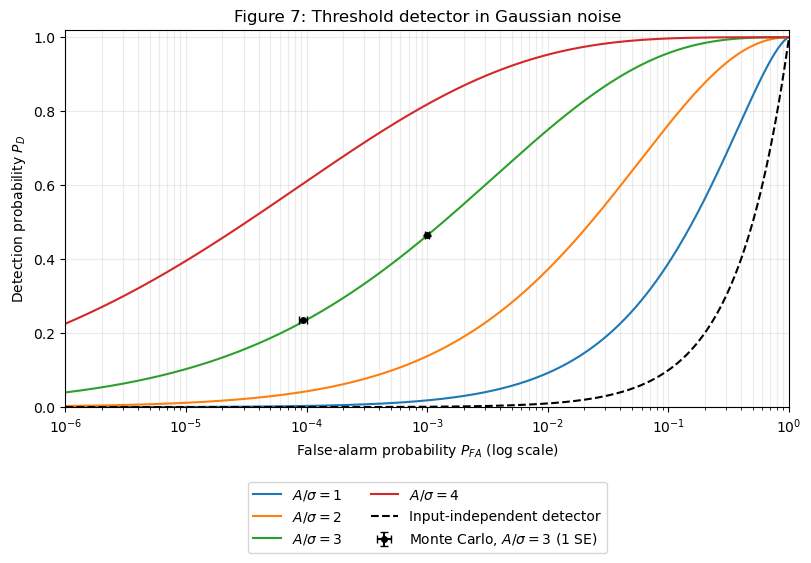

In [20]:
pfa_axis6 = np.geomspace(1e-6, 1.0, 700)
normalized_threshold6 = np.sqrt(2.0) * erfcinv(2.0*pfa_axis6)

fig7, ax7 = plt.subplots(
    figsize=(8, 5.5), layout="constrained"
)

for ratio6 in [1, 2, 3, 4]:
    pd_axis6 = q_function(normalized_threshold6-ratio6)

    ax7.semilogx(
        pfa_axis6,
        pd_axis6,
        label=fr"$A/\sigma={ratio6}$"
    )

ax7.semilogx(
    pfa_axis6,
    pfa_axis6,
    "k--",
    label="Input-independent detector"
)

ax7.errorbar(
    [row6["pfa_hat"] for row6 in mc_results6],
    [row6["pd_hat"] for row6 in mc_results6],
    xerr=[row6["se_fa"] for row6 in mc_results6],
    yerr=[row6["se_d"] for row6 in mc_results6],
    fmt="ko",
    markersize=4,
    capsize=3,
    label=r"Monte Carlo, $A/\sigma=3$ (1 SE)"
)

ax7.set(
    xlim=(1e-6, 1.0),
    ylim=(0.0, 1.02),
    xlabel=r"False-alarm probability $P_{FA}$ (log scale)",
    ylabel=r"Detection probability $P_D$",
    title="Figure 7: Threshold detector in Gaussian noise"
)

ax7.grid(True, which="both", alpha=0.25)
ax7.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2
)

plt.show()

At a fixed false-alarm probability, increasing $A/\sigma$ increases
the detection probability because the two Gaussian means are farther
apart in noise-standard-deviation units.

For $A/\sigma=3$, decreasing $P_{FA}$ from $10^{-3}$ to $10^{-6}$
raises $T/\sigma$ from 3.0902 to 4.7534 and reduces $P_D$
from 0.4641 to 0.0398.

In the fresh team-seed run, the false-alarm estimates were 0.000999
and 0.000094. Their estimated relative standard errors were 3.16%
and 7.29%, respectively

If a detector ignores $X$ and declares a detection with probability
$r$, then $P_{FA}=P_D=r$, so its ROC satisfies $P_D=P_{FA}$.
In Figure 7, this is the dashed black reference curve because the horizontal axis is logarithmic.


Step 6 thresholds a signed Gaussian measurement. Step 7 thresholds
a Rayleigh-distributed envelope, whose false-alarm probability is
$P_{FA}=\exp[-T^2/(2\sigma^2)]$, so Step 7 requires its own
Rayleigh threshold calculation.

## Step 7: The envelope detector, and what a wrong noise estimate costs

Step 7 Designed Treshold
  Target PFA |    T / sigma |   Treshold T
__________________________________________
1.000000e-02 |       3.0349 |       3.0349
1.000000e-03 |       3.7169 |       3.7169
1.000000e-04 |       4.2919 |       4.2919
1.000000e-06 |       5.2565 |       5.2565
Monte Carlo Verification
Number of Trails: 500000
False alarms: 520
Simulated PFA: 0.001040
Theoretical PFA: 0.001000
Standard Error: 4.558330e-05
             -1.00 |       0.8913 |    1.672125e-04 |                           0.17x
              0.00 |       1.0000 |    1.000082e-03 |                           1.00x
              1.00 |       1.1220 |    4.140414e-03 |                           4.14x
              2.00 |       1.2589 |    1.279825e-02 |                          12.80x
              3.00 |       1.4125 |    3.136579e-02 |                          31.37x


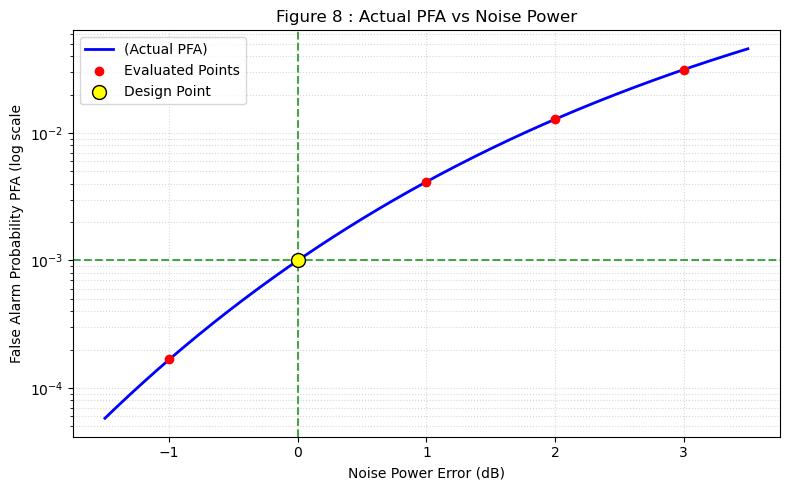

In [21]:
rng_step7 = rng.spawn(1)[0] 

sigma = 1 
pfa_targets = [1e-2, 1e-3, 1e-4, 1e-6]

print("Step 7 Designed Treshold") 
print(f"{'Target PFA':>12} | {'T / sigma' :>12} | {'Treshold T':>12}")
print("_" * 42)

thresholds = {} 
for pfa in pfa_targets: 
    t_over_sigma = np.sqrt(-2 * np.log(pfa))
    t_value = sigma *  t_over_sigma
    thresholds[pfa] = t_value
    print(f"{pfa:>12e} | {t_over_sigma:>12.4f} | {t_value:>12.4f}")

print("Monte Carlo Verification") 
N_trials = 500000
T_design = thresholds[1e-3]

noise = rng_step7.rayleigh(scale = sigma, size = N_trials)
false_alarms = np.sum(noise > T_design)
pfa_simulated = false_alarms / N_trials 

std_error = np.sqrt(pfa_simulated * (1 - pfa_simulated) / N_trials)
print(f"Number of Trails: {N_trials}")
print(f"False alarms: {false_alarms}")
print(f"Simulated PFA: {pfa_simulated:.6f}")
print(f"Theoretical PFA: {1e-3:.6f}")
print(f"Standard Error: {std_error:.6e}") 


delta_db_list = [-1, 0, 1, 2, 3]
T_design = 3.7169
sigma_assumed = 1.0

actual_pfa_list = []
for delta_db in delta_db_list:
    power_ratio = 10.0 ** (delta_db / 10.0)
    sigma_true = sigma * np.sqrt(power_ratio)
    actual_pfa = np.exp(-(T_design ** 2) / (2.0 * (sigma_true ** 2)))
    actual_pfa_list.append(actual_pfa)
    ratio = actual_pfa / 1e-3
    print(f"{delta_db:>18.2f} | {sigma_true:>12.4f} | {actual_pfa:>15.6e} | {ratio:>30.2f}x")

db_smooth = np.linspace(-1.5, 3.5, 300)
sigma_smooth = sigma * np.sqrt(10 ** (db_smooth / 10))
pfa_smooth = np.exp(-(T_design ** 2) / (2.0 * (sigma_smooth** 2))) 

plt.figure(figsize=(8,5))
plt.plot(db_smooth, pfa_smooth, label = "(Actual PFA)", color = "blue", linewidth = 2)
plt.scatter(delta_db_list, actual_pfa_list, color= "red", zorder = 5, label= "Evaluated Points")

plt.scatter([0], [1e-3], color = "yellow", edgecolor = "black", s=100, zorder= 6, label = "Design Point") 
plt.axhline(1e-3, color = "green", linestyle= "--" , alpha = .7)
plt.axvline(0, color = "green", linestyle= "--" , alpha = .7)

plt.yscale("log")
plt.xlabel("Noise Power Error (dB)")
plt.ylabel("False Alarm Probability PFA (log scale")
plt.title("Figure 8 : Actual PFA vs Noise Power")
plt.grid(True, which = "both", linestyle = ":", alpha = .5)
plt.legend(loc = "upper left")
plt.tight_layout()
plt.show()

## Step 8: Choosing the operating point

Using the previous Gaussian detector, we can derive the signal to noise ratio needed to get a $P_D = 0.9$ as a function of $P_{FA}$.

From Step 6, we know $P_{FA} = Q \frac{T}{\sigma}$ and $P_D = q \frac{T-A}{\sigma}$.

In order to get $$\frac{A}{\sigma}$$ we must subtract the two as $$\frac{T-A}{\sigma}$$ equals $$\frac{T}{\sigma} - \frac{A}{\sigma}$$.

From there we end up with $$Q^{-1}(P_{FA}) - Q^{-1}(P_D) = \frac{A}{\sigma}$$

Next, we must get the value of $Q^{-1}$.

We know Q, which is the probability of the Gaussian random variable being larger than a value x, can be represented by $$Q(x) =\frac{1}{2}(1-erf(\frac{x}{\sqrt{2}}))$$

To get the inverse of Q , we solve for x.

$$Q(x) =\frac{1}{2}(1-erf(\frac{x}{\sqrt{2}})) = P$$
$$\frac{P}{2} - 1 = erf(\frac{x}{\sqrt{2}}) $$
From here, we use inverse Q:
$$erf^{-1}(\frac{P}{2} - 1) = erf^{-1}(erf(\frac{x}{\sqrt{2}})) $$
$$\sqrt{2}erf^{-1}(\frac{P}{2} - 1) = Q^{-1}(P) $$

We can say $$\sqrt{2}{erf}^{-1}(\frac{P_{FA}}{2} - 1)  - \sqrt{2}{erf}^{-1}(\frac{0.9}{2} - 1) = \frac{A}{\sigma}$$

Step 8: Required Operating Points
       PFA      T/sigma      A/sigma    Amplitude dB
     1e-02     2.326348     3.607899          11.145
     1e-03     3.090232     4.371784          12.813
     1e-04     3.719016     5.000568          13.980
     1e-06     4.753424     6.034976          15.614


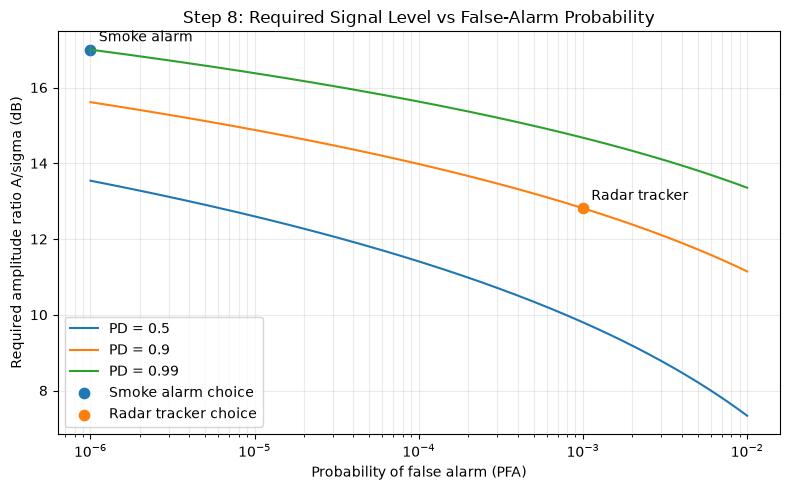


Example Operating Points
Smoke alarm: PFA=1e-06, PD=0.99, T/sigma=4.7534, A/sigma=7.0798, Amplitude ratio=17.00 dB
Radar tracker: PFA=1e-03, PD=0.90, T/sigma=3.0902, A/sigma=4.3718, Amplitude ratio=12.81 dB

Impact of +1 dB Noise-Power Uncertainty

Smoke alarm
Original PFA: 1e-06
Original PD: 0.990000
Actual PFA with fixed threshold: 1.13519e-05
Actual PD with fixed threshold: 0.980931
Actual PD after raising threshold to preserve PFA: 0.940197

Radar tracker
Original PFA: 0.001
Original PD: 0.900000
Actual PFA with fixed threshold: 0.00294204
Actual PD with fixed threshold: 0.873311
Actual PD after raising threshold to preserve PFA: 0.789914


In [1]:
# Import libraries needed for the entire project
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import ndtr
# Define Q-function
def q_function(x):
    return ndtr(-np.asarray(x))
#Set random number generator
rng = np.random.default_rng(2026)
#Desired false-alarm probabilities
pfa_values = np.array([1e-2, 1e-3, 1e-4, 1e-6])
#Desired detection probability
pd_target = 0.90
#Calculate threshold in units of noise standard deviation
#stats.norm.isf(pfa) is the inverse Q function
thresholds = stats.norm.isf(pfa_values)
#Calculate required signal-to-noise amplitude ratio
required_ratio = thresholds - stats.norm.isf(pd_target)
#Convert amplitude ratio to decibels
required_db = 20 * np.log10(required_ratio)
#Print results
print("Step 8: Required Operating Points")
print(f"{'PFA':>10} {'T/sigma':>12} "
      f"{'A/sigma':>12} {'Amplitude dB':>15}")
for pfa, t, a, db in zip(pfa_values, thresholds, required_ratio, required_db):
    print(f"{pfa:10.0e} {t:12.6f} {a:12.6f} {db:15.3f}")

#Plot required signal level versus PFA
pfa_plot = np.geomspace(1e-6, 1e-2, 500)
fig, ax = plt.subplots(figsize=(8, 5))
#Compare different detection probabilities
for pd in [0.50, 0.90, 0.99]:
    #Required signal-to-noise amplitude ratio
    a_req = stats.norm.isf(pfa_plot) - stats.norm.isf(pd)
    #Convert to decibels and plot
    ax.semilogx(pfa_plot, 20 * np.log10(a_req), label=f"PD = {pd}")
ax.set(xlabel="Probability of false alarm (PFA)", ylabel="Required amplitude ratio A/sigma (dB)", title="Step 8: Required Signal Level vs False-Alarm Probability")
ax.grid(True, which="both", alpha=0.25)
ax.legend()

#Choose example operating points
#These are example engineering choices, not universal requirements
choices = {"Smoke alarm": {"pfa": 1e-6, "pd": 0.99}, "Radar tracker": {"pfa": 1e-3, "pd": 0.90}}
#Mark the selected operating points on the graph
for name, c in choices.items():
    t = stats.norm.isf(c["pfa"])
    a = t - stats.norm.isf(c["pd"])
    ax.scatter([c["pfa"]], [20 * np.log10(a)], s=55, label=f"{name} choice")
    ax.annotate(name, (c["pfa"], 20 * np.log10(a)), xytext=(6, 6), textcoords="offset points")
ax.legend()
plt.tight_layout()
plt.show()

#Print the selected operating points
print("\nExample Operating Points")
for name, c in choices.items():
    t = stats.norm.isf(c["pfa"])
    a = t - stats.norm.isf(c["pd"])
    db = 20 * np.log10(a)
    print(f"{name}: PFA={c['pfa']:.0e}, " f"PD={c['pd']:.2f}, " f"T/sigma={t:.4f}, " f"A/sigma={a:.4f}, " f"Amplitude ratio={db:.2f} dB")

#Investigate +1 dB noise-power uncertainty
db_margin = 1.0
#Convert noise-power increase to noise standard-deviation factor
noise_scale = 10 ** (db_margin / 20)
print("\nImpact of +1 dB Noise-Power Uncertainty")
for name, c in choices.items():
    #Original design values
    t_nom = stats.norm.isf(c["pfa"])
    a_nom = t_nom - stats.norm.isf(c["pd"])
    #Case 1: Keep the original threshold fixed
    actual_pfa_fixed = float(stats.norm.sf(t_nom / noise_scale))
    actual_pd_fixed = float(q_function((t_nom - a_nom) / noise_scale))
    #Case 2: Increase threshold to preserve the original PFA
    actual_pd_adjusted = float(q_function(t_nom - a_nom / noise_scale))
    print(f"\n{name}")
    print(f"Original PFA: {c['pfa']:.6g}")
    print(f"Original PD: {c['pd']:.6f}")
    print(f"Actual PFA with fixed threshold: {actual_pfa_fixed:.6g}")
    print(f"Actual PD with fixed threshold: {actual_pd_fixed:.6f}")
    print(f"Actual PD after raising threshold to preserve PFA: " f"{actual_pd_adjusted:.6f}")


## Bonus A: Characteristic functions

## Bonus B: A distribution with no mean